# Material de aula - FACENS - Redes Neurais e Deep Learning

In [ ]:
#Neste versão o bias não é incluido dentro do vetor de pesos e os calculos são separados


## <center> TDNN e Séries Temporais - LABORATÓRIO 04 </center>

### As topologias candidatas para serem adotadas no mapeamento do problema acima são especificadas como se segue:

1. Rede 1: 05 entradas (p = 05) com N1 = 10
2. Rede 2: 10 entradas (p = 10) com N1 = 15
3. Rede 3: 15 entradas (p = 15) com N1 = 25

Utilize a função de ativação logística para todos os neurônios, taxa de aprendizado $ \eta = 0.1 $ , fator de momentum $\alpha = 0.8$  e precisão $\epsilon = 0.5 \cdot 10^{-6}$.

In [1]:
#CÉLULA TDNN-LIB-01
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

In [2]:
#CÉLULA TDNN-LIB-02
def loadDataFile(filename) :
    '''
    Esta função faz o carregamento de dados de um arquivo separado por virgulas (csv)
    
    Parametros
    -----------
    filename -> nome do arquivo de dados em formato csv
    
    
    Retorno
    -----------  
    dataframe contendo os dados do arquivo formatados numericamente.
    '''
    
    dfFile = pd.read_csv(filename, sep=';', decimal=',', thousands='.')
    return dfFile

In [3]:
#CÉLULA TDNN-LIB-03
def sigmoid(z) :
    '''
    Esta função faz o cálculo da função de ativação do tipo sigmoide
    
    Parametros
    -----------
    z -> valor do parametro a ser calculado em f(z)
    
    Retorno
    -----------  
    valor da função sigmoide correspondente ao parametro z
    '''    
    return 1/(1+np.exp(-z))

In [4]:
#CÉLULA TDNN-LIB-04
def tanh_function(z) :
    '''
    Esta função faz o cálculo da função de ativação do tipo tangente hiperbolica
    
    Parametros
    -----------
    z -> valor do parametro a ser calculado em f(z)
    
    Retorno
    -----------  
    valor da função tangente hiperbolica correspondente ao parametro z
    '''        
    return np.tanh(z)

In [5]:
#CÉLULA TDNN-LIB-05
def forward_step(vInputs, vWeights, vBias) : 
    '''
    Processa o forward step
    
    Parametros
    -----------
    vInputs  -> vetor/matriz com as entradas
    vWeights -> vetor/matriz com os vetores de pesos (é um vetor de matrizes)
    vBias    -> vetor/matriz com os vetores de bias  (é um vetor de matrizes)
    
    Retorno
    -------
    Este método retorna uma tupla contendo a saída das camadas da TDNN
    (Y_1, Y_2)
    '''
    
    W_1 = vWeights[0]
    W_2 = vWeights[1]
    
    B_1 = vBias[0]
    B_2 = vBias[1]

    #FORWARD STEP
    #Calcula saída do TDNN para todas as amostras, de uma vez.
    Y_0 = vInputs #so para ficar uniforme a nomenclatura dos termos
    I_1 = W_1 @ Y_0 + B_1
    Y_1 = sigmoid(I_1) #Função sigmoide na camada oculta, g1

    I_2 = W_2 @ Y_1 + B_2
    Y_2 = sigmoid(I_2) #Função linear na camada de saida, g2
    #FIM DO FORWARD STEP
    
    return (Y_1, Y_2)

In [6]:
#CÉLULA TDNN-LIB-06
def calcMSE(vInputs, vOutputs, vWeights, vBias) : 
    '''
    Calcula o Erro Quadratico Medio (Mean Squared Error) da TDNN
    
    Parametros
    -----------
    vInputs  -> vetor/matriz com as entradas
    vOutputs -> vetor/matriz com os vetores dos dados
    vWeights -> vetor/matriz com os vetores de pesos (é um vetor de matrizes)
    vBias    -> vetor/matriz com os vetores de bias  (é um vetor de matrizes)
    
    Retorno
    -------
    Este método retorna o valor de MSE para o conjunto de dados e pesos do TDNN
    '''
    
    (_, Y_2) = forward_step(vInputs, vWeights, vBias)
    nSamples = vInputs.shape[1]
       
    E_k = 1/2 * (vOutputs - Y_2)**2
    E_k = np.sum(E_k, axis=1)
    MSE = np.sum(E_k) / nSamples
    
    return np.asscalar(MSE)

# 1 - Implementação do algoritmo de treinamento da TDNN

Utilizando Jupyter e NumPy: para o problema apresentado, complete o código para construir as funções de treinamento da TDNN

## 1.1 - Ajuste o código que realiza o treinamento da TDNN

In [7]:
#CÉLULA TDNN-LIB-07
def tdnn_train_batch(alpha,eta, epsilon, vInputs, vOutputs, dictLayers, max_epochs) :
    '''
    Algoritmo de treinamento da TDNN
    
    Parametros
    -----------
    eta         -> taxa de aprendizado
    epsilon     -> margem de erro
    vInputs     -> vetor/matriz com as entradas
    vOutputs    -> vetor/matriz com as saidas
    dictLayers  -> dicionario que descreve as camadas da rede {'nLayers' : 'xxx', vLayers : vvv}, onde nLayers representa 
                   o numero de camadas e vLayers é um vetor linha contedo o tamanho de cada camada
    max_epochs -> criterio de parada por epocas de treinamento
    
    Retorno
    -------
    Este método retorna uma tupla contendo o vetor de pesos ajustado e o numero de epocas executadas no treinamento.
    '''
        
    #Determine numero de entradas do TDNN e o numero de amostras
    nInputs  = vInputs.shape[0]
    nSamples = vInputs.shape[1]
    
    indexLayer = 1
    nNeurons      = dictLayers['vLayers'][indexLayer]   #Numero de neurons da camada 'indexLayer'
    nConnections  = dictLayers['vLayers'][indexLayer-1] #Numero de neurons da camada 'indexLayer-1'
    
    # Wji = j-esimo neuron de uma cada ao i-esimo sinal da camada de entrada (na primeira matriz de pesos)
    #assim, todos os sinais de entrada de um neuronio ficam na linha e cada linha contem 1 neuronio
    W_1 = np.random.rand(nNeurons, nConnections);
    B_1 = np.random.rand(nNeurons, 1);
    
    #IMPLEMENTE O CÓDIGO AQUI - INICIO
    #CRIE VARIAVEIS PARA ARMAZENAR AS Matrizes das iterações anteriores para uso de momentum

    #IMPLEMENTE O CÓDIGO AQUI - INICIO
    
    W_1_old = W_1
    B_1_old = B_1

    indexLayer    = 2
    nNeurons      = dictLayers['vLayers'][indexLayer]   #Numero de neurons da camada 'indexLayer'
    nConnections  = dictLayers['vLayers'][indexLayer-1] #Numero de neurons da camada 'indexLayer-1'

    # Wji = j-esimo neuron de uma cada ao i-esimo sinal da camada de entrada (na primeira matriz de pesos)
    #assim, todos os sinais de entrada de um neuronio ficam na linha e cada linha contem 1 neuronio
    W_2 = np.random.rand(nNeurons, nConnections);
    B_2 = np.random.rand(nNeurons, 1);
   
    #IMPLEMENTE O CÓDIGO AQUI - INICIO
    #CRIE VARIAVEIS PARA ARMAZENAR AS Matrizes das iterações anteriores para uso de momentum

    #IMPLEMENTE O CÓDIGO AQUI - INICIO
    W_2_old = W_2
    B_2_old = B_2
    #Monte o loop de cálculo do erro e ajuste dos pesos
    bError = True
    MSE = [] # MSE: Mean Squared Error
        
    for epochCounter in range(max_epochs) :
        Y_0 = vInputs #esta atribuição é apenas para manter uniformidade de nomenclatura
        (Y_1, Y_2) = forward_step(vInputs, [W_1, W_2], [B_1, B_2])       

        #INICIO - BACKWARD STEP
        #A derivada de g2 é igual a Y_2 * (1 - Y_2)
        #Ajuste de pesos Camada Oculta - Camada de Saída
        diff_g2 = Y_2 * (1 - Y_2)
        #Gradiente local
        delta_2 = (vOutputs - Y_2) * diff_g2#gradiente
        
        #IMPLEMENTE O CÓDIGO AQUI - INICIO
        #AJUSTE OS VALORES DE W_2 E B_2        
        #Ajuste dos pesos
        W_2 += eta * delta_2 @ Y_1.T + alpha * (W_2 - W_2_old)
        B_2 += eta * np.sum(delta_2, axis=1, keepdims=True) + alpha * (B_2 - B_2_old)
        
        #ATUALIZE OS VALORES DOS PESOS NAS VARIAVEIS AUXILIARES
        W_2_old = W_2
        B_2_old = B_2
        #IMPLEMENTE O CÓDIGO AQUI - FIM
        
        #Ajuste de pesos Camada Entrada - Camada Oculta
        #A derivada de g1(I_1) é igual a g1(I_1)*(1 - g1(I_1)) ou seja, Y_1*(1 - Y_1)
        diff_g1 = Y_1 * (1 - Y_1)

        #Gradiente local
        delta_1 = (W_2.T @ delta_2) * diff_g1
        
        #IMPLEMENTE O CÓDIGO AQUI - INICIO
        #AJUSTE OS VALORES DE W_2 E B_2        
        #Ajuste dos pesos
        W_1 += eta * delta_1 @ Y_0.T + alpha * (W_1 - W_1_old)
        B_1 += eta * np.sum(delta_1, axis=1, keepdims=True) + alpha * (B_1 - B_1_old)
        
        #ATUALIZE OS VALORES DOS PESOS NAS VARIAVEIS AUXILIARES
        W_1_old = W_1
        B_1_old = B_1
        #IMPLEMENTE O CÓDIGO AQUI - FIM
        #FIM - BACKWARD STEP

        #Calcula o Erro Quadratico Medio
        MSE_temp = calcMSE(vInputs, vOutputs, [W_1, W_2], [B_1, B_2])
        MSE.append( MSE_temp )
        
        print( 'Epoch = {} - MSE = {}'.format(epochCounter, MSE_temp))
        
        if( epochCounter > 0 and abs(MSE[epochCounter] - MSE[epochCounter-1]) < epsilon ) :
            break
    
    return (W_1, W_2, B_1, B_2, MSE)

## 1.3 - Ajuste o código que realiza o treinamento ONLINE

In [8]:
#CÉLULA TDNN-LIB-07
def tdnn_train_online(eta, epsilon, vInputs, vOutputs, dictLayers, max_epochs) :
    '''
    Algoritmo de treinamento da TDNN
    
    Parametros
    -----------
    eta         -> taxa de aprendizado
    epsilon     -> margem de erro
    vInputs     -> vetor/matriz com as entradas
    vOutputs    -> vetor/matriz com as saidas
    dictLayers  -> dicionario que descreve as camadas da rede {'nLayers' : 'xxx', vLayers : vvv}, onde nLayers representa 
                   o numero de camadas e vLayers é um vetor linha contedo o tamanho de cada camada
    max_epochs -> criterio de parada por epocas de treinamento
    
    Retorno
    -------
    Este método retorna uma tupla contendo o vetor de pesos ajustado e o numero de epocas executadas no treinamento.
    '''
    
    #IMPLEMENTE O CÓDIGO AQUI
    #DICA: FAÇA FUNCIONAR O TREINAMENTO PARA O MODO BATCH, COPIE E COLE O CODIGO AQUI PARA MODIFICAR PARA ONLINE
    
    
    
    return (W_1, W_2, B_1, B_2, MSE)

In [28]:
#CÉLULA TDNN-LIB-08
def tdnn_operation(vInputs, vWeights, vBias) :
    '''
    Algoritmo de operação da TDNN
    
    Parametros
    -----------
    vInputs  -> vetor/matriz com as entradas
    vOutputs -> vetor/matriz com as saidas
    vWeights -> vetor/matriz com os vetores de pesos (é um vetor de matrizes)
    vBias    -> vetor/matriz com os vetores de bias  (é um vetor de matrizes)
    
    Retorno
    -------
    Este método retorna o valor de saída do TDNN
    '''
    
    (_, Y_2) = forward_step(vInputs, vWeights, vBias)    
    return (Y_2)

## 1.4 - Crie a função de janelamento dos dados de entrada

In [17]:
#CÉLULA TDNN-LIB-09
def tdnn_windowing2(nInputs, vInputs) :
    '''
    Realiza o janelamento dos dados a serem processados pela TDNN
    
    Parametros
    -----------
    nInputs  -> quantidade de entradas da Rede TDNN
    vInputs  -> vetor/matriz com as entradas
    
    
    Retorno
    -------
    Este método retorna o valor de saída do TDNN
    '''
    #IMPLEMENTE O CÓDIGO AQUI - INICIO
    start = 0
    datasize = len(vInputs)
    X = np.empty((0, start + nInputs + 1))
    
    for _ in range (datasize - nInputs):
        newRow = vInputs[start : start + nInputs].T
        newRow = newRow[:,::-1]#inverte todas as linhas, ordem do slide
        newRow = np.concatenate((newRow, vInputs[start + nInputs].reshape(-1,1)), axis=1)
        
        X = np.concatenate((X,newRow), axis=0)#1 linha com np entradas e 1 saída
        start+=1
    
    
    return X

In [18]:
dfTemp = pd.read_csv('Lab04_training.csv')
vInputs = np.array(dfTemp['x1']).reshape(-1,1)
nInputs = 5

X = tdnn_windowing2(nInputs,vInputs)
print(X)
#x4,x3,x2,x1,x0 > saída
#x5,x4,x3,x2,x1 > saída

[[7.192e+03 3.609e+03 4.405e+03 1.023e+03 1.701e+03 2.258e+03]
 [2.258e+03 7.192e+03 3.609e+03 4.405e+03 1.023e+03 3.175e+03]
 [3.175e+03 2.258e+03 7.192e+03 3.609e+03 4.405e+03 1.270e+02]
 [1.270e+02 3.175e+03 2.258e+03 7.192e+03 3.609e+03 4.290e+03]
 [4.290e+03 1.270e+02 3.175e+03 2.258e+03 7.192e+03 5.440e+02]
 [5.440e+02 4.290e+03 1.270e+02 3.175e+03 2.258e+03 8.000e+03]
 [8.000e+03 5.440e+02 4.290e+03 1.270e+02 3.175e+03 4.500e+02]
 [4.500e+02 8.000e+03 5.440e+02 4.290e+03 1.270e+02 4.268e+03]
 [4.268e+03 4.500e+02 8.000e+03 5.440e+02 4.290e+03 1.120e+02]
 [1.120e+02 4.268e+03 4.500e+02 8.000e+03 5.440e+02 3.218e+03]
 [3.218e+03 1.120e+02 4.268e+03 4.500e+02 8.000e+03 2.185e+03]
 [2.185e+03 3.218e+03 1.120e+02 4.268e+03 4.500e+02 7.240e+03]
 [7.240e+03 2.185e+03 3.218e+03 1.120e+02 4.268e+03 3.516e+03]
 [3.516e+03 7.240e+03 2.185e+03 3.218e+03 1.120e+02 4.420e+03]
 [4.420e+03 3.516e+03 7.240e+03 2.185e+03 3.218e+03 9.840e+02]
 [9.840e+02 4.420e+03 3.516e+03 7.240e+03 2.185e+03 1.7

# 2 - Implementação e testes do modelo da Rede TDNN

### O preço de uma determinada mercadoria disposta para ser comercializada no mercado financeiro de ações possui um histórico de variação de valor conforme mostrado no dataset disponível.

### Um pool de pesquisadores estará tentando aplicar redes neurais para tentar prever o comportamento futuro deste processo. Assim, pretende-se utilizar uma arquitetura perceptron multicamadas, com topologia “Time Delay” (TDNN), conforme mostrada na figura abaixo: 

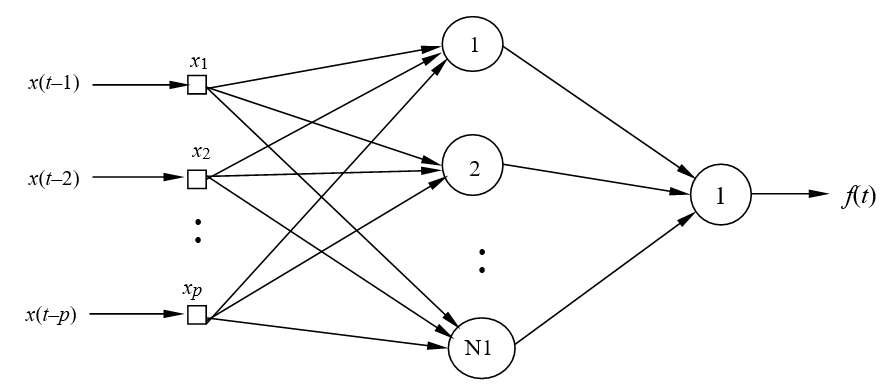



*Fonte*:  SILVA, I.N. – Sistemas Inteligentes – Notas de Aula da disciplina **Redes Neurais Artificiais** – USP São Carlos, 2012

## TDNN - inicio

# 2.1 - Configuração dos hiperparâmetros

In [34]:
#CÉLULA TDNN-MAIN-01

#IMPLEMENTE O CÓDIGO AQUI - INICIO

#Parâmetros
alpha    = 0.8
eta      = 0.001
epsilon  = 0.0000005
nInputs  = 5
nHidden  = 10
nOutputs = 1
max_epochs =20000 
dictLayers = {'nLayers':2, 'vLayers':np.array([nInputs, nHidden, nOutputs])}

# 2.2 - Carga dos dados e execução do treinamento

In [35]:
#CÉLULA TDNN-MAIN-01

#IMPLEMENTE O CÓDIGO AQUI - INICIO
# 1 - FAÇA O CARREGAMENTO DOS DADOS
# 2 - FAÇA O JANELAMENTO DOS DADOS DE ENTRADA
# 3 - SEPARE EM DOIS VETORES DE DADOS: ENTRADAS E SAIDAS
# 4 - EXECUTE O TREINAMENTO E VERIFIQUE A CONVERGÊNCIA

#Carrega dados - Treino
dfTrainingFile = loadDataFile('Lab04_training.csv')
dfTrainingFile

vInputs = np.array(dfTrainingFile['x1']).reshape(-1,1)
X = tdnn_windowing2(nInputs,vInputs)

vInputs = X[:, 0:nInputs]
vOutputs = X[:, nInputs + nOutputs -1].reshape(-1,nOutputs)
nSamples = len(vInputs)

(W_1,W_2,B_1,B_2,MSE) = tdnn_train_batch(alpha,eta,epsilon,vInputs.T,vOutputs.T,dictLayers,max_epochs)

Epoch = 0 - MSE = 0.24989164929318855
Epoch = 1 - MSE = 0.24988612543678212
Epoch = 2 - MSE = 0.24988058007246544
Epoch = 3 - MSE = 0.2498750130752507
Epoch = 4 - MSE = 0.24986942431918518
Epoch = 5 - MSE = 0.24986381367734084
Epoch = 6 - MSE = 0.2498581810218054
Epoch = 7 - MSE = 0.24985252622367304
Epoch = 8 - MSE = 0.24984684915303393
Epoch = 9 - MSE = 0.24984114967896537
Epoch = 10 - MSE = 0.24983542766952133
Epoch = 11 - MSE = 0.24982968299172295
Epoch = 12 - MSE = 0.24982391551154823
Epoch = 13 - MSE = 0.2498181250939215
Epoch = 14 - MSE = 0.24981231160270365
Epoch = 15 - MSE = 0.24980647490068125
Epoch = 16 - MSE = 0.24980061484955632
Epoch = 17 - MSE = 0.2497947313099354
Epoch = 18 - MSE = 0.24978882414131875
Epoch = 19 - MSE = 0.24978289320208938
Epoch = 20 - MSE = 0.24977693834950207
Epoch = 21 - MSE = 0.24977095943967223
Epoch = 22 - MSE = 0.24976495632756432
Epoch = 23 - MSE = 0.24975892886698037
Epoch = 24 - MSE = 0.2497528769105486
Epoch = 25 - MSE = 0.24974680030971153
E

# 2.3 - Verificação dos resultados do treinamento

In [36]:
#Verifica resultados
#IMPLEMENTE O CÓDIGO AQUI - INICIO
# EXECUTE A OPERAÇÃO COM OS DADOS DE TREINAMENTO E VERIFIQUE O RESULTADO 
#PLOTANDO UM GRÁFICO ENTRE OS DADOS DE PREDIÇÃO VERSUS OS DADOS ESPERADOS
y_real = tdnn_operation(vInputs.T, [W_1,W_2],[B_1,B_2])
y_real = y_real.T

E_abs = np.abs(vOutputs - y_real)
E_rel = E_abs / y_real
E_rel_avg = np.sum(E_rel) / nSamples

print(E_rel_avg)

0.3973272638451482


# 2.4 - Verificação dos resultados do conjunto de teste

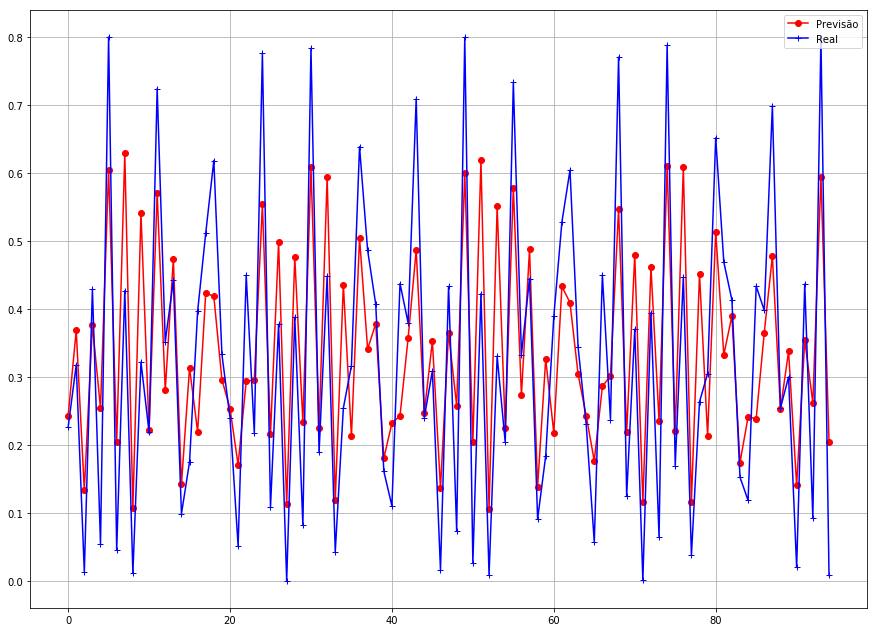

In [41]:
#Carrega dados - Teste
# EXECUTE A OPERAÇÃO COM OS DADOS DE TESTE E VERIFIQUE O RESULTADO 
#PLOTANDO UM GRÁFICO ENTRE OS DADOS DE PREDIÇÃO VERSUS OS DADOS ESPERADOS
dfTestFile = loadDataFile('Lab04_operation_R1.csv')

plt.figure(figsize=(15,11))
plt.plot(range(len(y_real)),y_real, 'ro-')
plt.plot(range(len(vOutputs)),vOutputs, 'b+-')
plt.gca().legend(('Previsão','Real'))
plt.grid()
plt.show()


# 2.5 - Calcule o erro absoluto médio da TDNN

In [43]:
#Verifica resultados 
y_pred = y_pred.T

E_abs = np.abs(vOutputs - y_pred)
E_rel = E_abs / y_pred
E_rel_avg = np.sum(E_rel) / nSamples

print(E_rel_avg)

outVar = np.var(y_pred - vOutputs)
print(outVar)


NameError: name 'y_pred' is not defined

In [ ]:
#Gráfico de dados previstos VERSUS dados reais

In [ ]:
#Erro Quadratico Medio
